# Риск автоматизации профессий под воздействием ИИ
**Финальный проект Data Science · Нуркыз Алиева**

**Заказчик:** HR и L&D-отделы компаний Кыргызстана (в первую очередь банков).

**Задача бизнеса:** понять, какие должности в штате попадают в зону риска автоматизации, и на какие навыки
направить бюджет переобучения, чтобы не отстать от конкурентов во внедрении ИИ.

**ML-задача:** многоклассовая классификация. Объект — профессия, признаки — важность ~160 навыков,
знаний, способностей и рабочих действий (O\*NET), цель — класс риска автоматизации:
**низкий** (< 0,3), **средний** (0,3–0,7), **высокий** (≥ 0,7) по вероятности Frey & Osborne.

| Источник | Что даёт | Роль |
|---|---|---|
| Frey & Osborne (2013/2017), 702 профессии | вероятность автоматизации | целевая переменная |
| O\*NET 31.0 (данные обновлены до 08/2026): Skills, Knowledge, Abilities, Work Activities | важность элемента для профессии, шкала 1–5 | признаки |
| GPTs are GPTs (OpenAI / UPenn, 2023) | доля задач, ускоряемых генеративным ИИ | вторая ось анализа |
| Anthropic Economic Index (2025–2026) | реальное использование ИИ, доля автоматизации, экспозиция к роботам | проверка меток и доп. оси для HR |
| hh (вакансии Кыргызстана, парсинг, октябрь 2026) | спрос, зарплаты, ключевые навыки | применение к рынку КР |
| lalafo.kg (объявления о работе, парсинг, октябрь 2026) | объём спроса и зарплаты, в т.ч. неформальный сектор | применение к рынку КР |
| LinkedIn Skills on the Rise 2025–2026, WEF Future of Jobs 2025 | мировые тренды навыков | вес в рекомендациях по обучению |

### Запуск в Google Colab
1. Загрузите папку проекта `final_project` (с подпапками `src`, `data`, `models`) на свой Google Диск.
2. Запустите ячейку ниже и разрешите доступ к Диску — она сама найдёт папку проекта и перейдёт в неё.

На своём компьютере (Jupyter / VS Code) эта ячейка ничего не делает.

In [1]:
import sys, os, glob
if "google.colab" in sys.modules and not os.path.exists("src/skills_ru.py"):
    !pip -q install adjustText
    from google.colab import drive
    drive.mount("/content/drive")
    found = glob.glob("/content/drive/MyDrive/**/src/skills_ru.py", recursive=True)
    if not found:
        raise FileNotFoundError("Не нашла папку проекта на Google Диске: загрузите папку final_project целиком")
    os.chdir(os.path.dirname(os.path.dirname(found[0])))
print("Рабочая папка:", os.getcwd(), "| src найден:", os.path.exists("src/skills_ru.py"))

Рабочая папка: /root/proj | src найден: True


In [2]:
import warnings, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay, recall_score, accuracy_score
from sklearn.inspection import permutation_importance
import joblib, sys
sys.path.append("src")
from skills_ru import SKILL_RU, TRAINABLE, WEF_TREND, WEF_WEIGHT, LINKEDIN_TREND, trend_weight, feature_ru
from adjustText import adjust_text

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
RANDOM_STATE = 42
CLASSES = ["low", "medium", "high"]
CLASS_RU = {"low": "низкий", "medium": "средний", "high": "высокий"}
RISK_COLORS = {"low": "#f5c4a8", "medium": "#eb6834", "high": "#a33a12"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10})
DATA = Path("data")

## 1. Сборка датасета
`src/build_dataset.py` разворачивает O\*NET в широкую таблицу (одна строка — профессия, столбец — навык,
значение — важность по шкале IM 1–5), усредняет подкоды (`11-1011.03` → `11-1011`) и присоединяет её к
Frey & Osborne по коду профессии. Берём **актуальную версию O\*NET 31.0** (оценки обновлялись до августа 2026).
Она размечена в новых кодах O\*NET-SOC 2019, а таблица Frey & Osborne — в старых SOC 2010, поэтому коды
переводятся через **официальный кроссвок O\*NET «2010 → 2019»**. 8 профессий (например, финансовые аналитики)
в новой таксономии ещё не оценены — для них берётся профиль из O\*NET 24.0 (столбец `onet_version`).
Для агрегированных кодов (например, `29-1060` «Врачи») берётся среднее по подкодам.

In [3]:
import subprocess, sys
subprocess.run([sys.executable, "src/build_dataset.py"], check=True)
df = pd.read_csv(DATA / "processed" / "occupations_dataset.csv")
GROUPS = {"sk": "Навыки", "kn": "Знания", "ab": "Способности", "wa": "Рабочие действия"}
FEATS = [c for c in df.columns if c[:3] in ("sk_", "kn_", "ab_", "wa_")]
print("Размер:", df.shape, "| признаков O*NET:", len(FEATS))
print(df["onet_version"].value_counts(dropna=False).to_dict())
print({GROUPS[g]: sum(c.startswith(g + "_") for c in FEATS) for g in GROUPS})
df.head(3)

(702, 175) без признаков O*NET: 9
Размер: (702, 175) | признаков O*NET: 161
{'O*NET 31.0': 685, nan: 9, 'O*NET 24.0': 8}
{'Навыки': 35, 'Знания': 33, 'Способности': 52, 'Рабочие действия': 41}


,soc,occupation,automation_prob,education,employment,median_wage,sk_Active Learning,sk_Active Listening,sk_Critical Thinking,sk_Learning Strategies,sk_Mathematics,sk_Monitoring,sk_Reading Comprehension,sk_Science,sk_Speaking,...,wa_Resolving Conflicts and Negotiating with Others,wa_Scheduling Work and Activities,wa_Selling or Influencing Others,wa_Staffing Organizational Units,wa_Thinking Creatively,wa_Training and Teaching Others,wa_Updating and Using Relevant Knowledge,onet_version,genai_exposure_human,genai_exposure_gpt4,aei_automation_share,aei_usage_pct,observed_exposure,robot_exposure_index,risk_class
0,51-4033,"Grinding, Lapping, Polishing and Buffing Machi...",0.95,High school diploma or equivalent,74600,32890.0,2.50,2.75,2.88,2.00,2.38,2.88,3.00,1.5,2.75,...,2.46,2.72,1.86,2.00,2.91,3.34,3.21,O*NET 31.0,0.064516,0.064516,NaN,0.00000,0.0000,0.8750,high
1,51-9012,"Separating, Filtering, Clarifying, Precipitati...",0.88,High school diploma or equivalent,47160,38360.0,2.88,3.00,3.12,2.75,2.62,3.12,3.00,2.5,2.88,...,2.35,2.27,1.69,1.95,2.81,3.11,2.87,O*NET 31.0,0.085714,0.142857,NaN,0.00000,0.0000,0.9375,high
2,41-4012,"Sales Representatives, Wholesale and Manufactu...",0.85,High school diploma or equivalent,1404050,57140.0,3.12,4.00,3.50,2.25,2.25,3.12,3.38,1.0,4.00,...,3.66,3.12,4.88,1.15,3.93,2.22,4.40,O*NET 31.0,0.706897,0.620690,0.287,0.11924,0.6279,0.1000,high


### Исходная таблица Frey & Osborne
Источник — статья C. Frey и M. Osborne (Оксфорд) *The Future of Employment* (2013, журнальная версия 2017).
Одна строка — одна профессия США по классификатору SOC 2010; всего 702 профессии.

| Столбец | Что означает | Используем? |
|---|---|---|
| `_ - code` | код профессии SOC, например `43-3071` (операционист) | ключ для соединения с O\*NET |
| `occupation` | название профессии | для отчётов |
| `prob` | вероятность автоматизации 0–1 | **целевая переменная** (после разбиения на 3 класса) |
| `education` | типичный уровень образования для входа в профессию | признак (порядковая шкала 0–7) |
| `median_ann_wage` | медианная годовая зарплата в США, $ | признак (логарифм) |
| `numbEmployed` | число занятых в США, май 2016 | только для описания |
| `_ - rank` | место в рейтинге по `prob` (1 — меньше всего риск) | **нет** — утечка ответа |
| `probability`, `employed_may2016`, `Average annual wage`, `average_ann_wage` | дубликаты столбцов выше | нет |
| `short occupation`, `len` | укрупнённая группа профессий и длина её названия | нет |

In [4]:
fo_raw = pd.read_csv(DATA / "raw" / "frey_osborne.csv")
print("Размер:", fo_raw.shape)
fo_raw[["_ - code", "occupation", "prob", "education", "median_ann_wage", "numbEmployed"]] \
    .set_index("occupation").loc[["Cashiers", "Tellers", "Loan Officers", "Accountants and Auditors",
                                  "Software Developers, Applications", "Lawyers"]]

Размер: (702, 13)


,_ - code,prob,education,median_ann_wage,numbEmployed
occupation,,,,,
Cashiers,41-2011,0.970,No formal educational credential,20180.0,3541010
Tellers,43-3071,0.980,High school diploma or equivalent,27260.0,496760
Loan Officers,13-2072,0.980,Bachelor's degree,63650.0,305700
Accountants and Auditors,13-2011,0.940,Bachelor's degree,68150.0,1246540
"Software Developers, Applications",15-1132,0.042,Bachelor's degree,100080.0,794000
Lawyers,23-1011,0.035,Doctoral or professional degree,118160.0,619530


### Карта данных: что откуда и зачем
**702 строки — это не страна, а профессии.** Каждая строка — одна профессия из мирового справочника
(SOC/O\*NET — стандарт, который используют ILO, OECD и WEF). Казахстанские данные в модели не участвуют.

In [5]:
vac_kg = pd.read_csv(DATA / "raw" / "hh_kg_vacancies.csv")
genai = pd.read_csv(DATA / "raw" / "gpts_are_gpts_occ_level.csv")
data_map = pd.DataFrame([
    ["Мир: профессии × навыки (O*NET 31.0, 2026)", f"{len(df)} профессий × {len(FEATS)} навыков", "признаки модели", "обучение"],
    ["Мир: риск автоматизации (Frey & Osborne, Оксфорд)", f"{df['automation_prob'].notna().sum()} профессий", "целевая переменная", "обучение"],
    ["Мир: экспозиция к GenAI (OpenAI / UPenn, 2023)", f"{len(genai)} профессий", "вторая ось риска", "анализ"],
    ["Мир: реальное использование ИИ и роботы (Anthropic Economic Index, 2025–2026)",
     f"{df['observed_exposure'].notna().sum()} профессий", "проверка меток, доп. оси", "анализ"],
    ["Мир: тренды навыков (WEF 2025 + LinkedIn Skills on the Rise 2025–2026)", "22 обучаемых навыка размечены", "вес в рекомендациях", "продукт"],
    ["Кыргызстан: вакансии hh (20.10.2026)", f"{len(vac_kg)} вакансий, {vac_kg['query'].nunique()} должностей, "
     f"{(vac_kg['city'].fillna('').str.startswith('Бишкек')).mean():.0%} — Бишкек", "спрос, зарплаты, навыки", "применение"],
    ["Кыргызстан: объявления lalafo.kg (21.10.2026)", f"{int(pd.read_csv(DATA / 'raw' / 'lalafo_kg_vacancies.csv')['title_match'].sum())} релевантных объявлений из 1231 собранных",
     "объём спроса, зарплаты", "применение"],
], columns=["Источник", "Объём", "Роль", "Этап"])
data_map

,Источник,Объём,Роль,Этап
0,"Мир: профессии × навыки (O*NET 31.0, 2026)",702 профессий × 161 навыков,признаки модели,обучение
1,"Мир: риск автоматизации (Frey & Osborne, Оксфорд)",702 профессий,целевая переменная,обучение
2,"Мир: экспозиция к GenAI (OpenAI / UPenn, 2023)",923 профессий,вторая ось риска,анализ
3,Мир: реальное использование ИИ и роботы (Anthr...,665 профессий,"проверка меток, доп. оси",анализ
4,Мир: тренды навыков (WEF 2025 + LinkedIn Skill...,22 обучаемых навыка размечены,вес в рекомендациях,продукт
5,Кыргызстан: вакансии hh (20.10.2026),"390 вакансий, 59 должностей, 82% — Бишкек","спрос, зарплаты, навыки",применение
6,Кыргызстан: объявления lalafo.kg (21.10.2026),551 релевантных объявлений из 1231 собранных,"объём спроса, зарплаты",применение


## 2. Обзор данных

In [6]:
df[["automation_prob", "median_wage", "employment", "genai_exposure_human"]].describe().round(3)

,automation_prob,median_wage,employment,genai_exposure_human
count,702.000,702.000,702.000,686.000
mean,0.536,51345.468,186835.726,0.271
std,0.368,26912.979,423140.174,0.208
min,0.003,19290.000,370.000,0.000
25%,0.110,33355.000,17307.500,0.078
50%,0.640,44370.000,48990.000,0.245
75%,0.890,61652.500,151702.500,0.447
max,0.990,232870.000,4528550.000,0.844


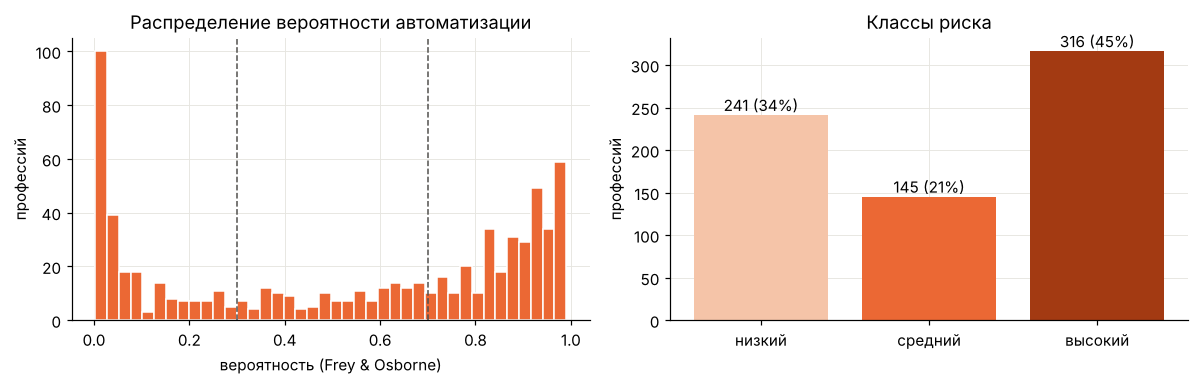

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df["automation_prob"], bins=40, color="#eb6834", edgecolor="white")
for t in (0.3, 0.7): ax[0].axvline(t, color="#52514e", ls="--", lw=1)
ax[0].set(title="Распределение вероятности автоматизации", xlabel="вероятность (Frey & Osborne)", ylabel="профессий")
vc = df["risk_class"].value_counts().reindex(CLASSES)
ax[1].bar([CLASS_RU[c] for c in CLASSES], vc.values, color=[RISK_COLORS[c] for c in CLASSES])
for i, v in enumerate(vc.values): ax[1].text(i, v + 5, f"{v} ({v/vc.sum():.0%})", ha="center")
ax[1].set(title="Классы риска", ylabel="профессий"); plt.tight_layout(); plt.show()

**Вывод.** Распределение бимодальное: большинство профессий либо почти точно автоматизируемы, либо почти
точно нет. Средний класс самый маленький (21%) и «размазан» между полюсами — ожидаем, что он будет
самым трудным для модели. Дисбаланс умеренный → `class_weight="balanced"` и метрика **macro-F1**.

## 3. Очистка: пропуски, дубликаты, выбросы, аномалии

In [8]:
print("Дубликаты кодов SOC:", df["soc"].duplicated().sum())
miss = df[FEATS].isna().any(axis=1)
print("Профессий без признаков O*NET:", miss.sum())
print(df.loc[miss, ["soc", "occupation"]].to_string(index=False))

Дубликаты кодов SOC: 0
Профессий без признаков O*NET: 9
    soc                                                      occupation
39-4831 Funeral Service Managers, Directors, Morticians and Undertakers
29-9799       Healthcare Practitioners and Technical Workers, All Other
49-9799         Installation, Maintenance and Repair Workers, All Other
29-2799                 Health Technologists and Technicians, All Other
47-4799                     Construction and Related Workers, All Other
31-9799                           Healthcare Support Workers, All Other
25-3999                             Teachers and Instructors, All Other
15-1799                                 Computer Occupations, All Other
51-9399                                   Production Workers, All Other


Это «сборные» категории вида «… All Other», у которых в O\*NET нет собственного профиля навыков.
Восстановить признаки честно нельзя, поэтому **удаляем 9 строк** (1,3% данных).

Значений вне шкалы 1–5: 0 | почти константных признаков: 0


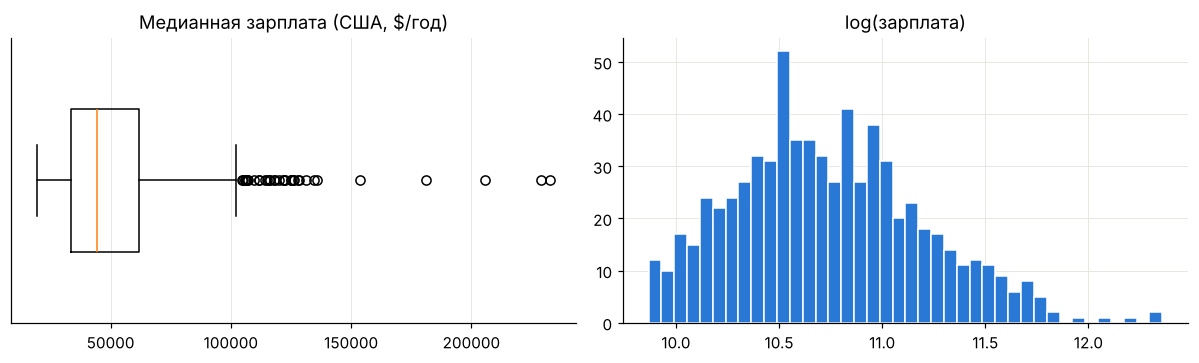

Выбросов по зарплате (IQR): 35 — это врачи, топ-менеджеры, пилоты: реальные значения, не ошибки. Не удаляем, берём логарифм.


In [9]:
df = df[~miss].reset_index(drop=True)
out_range = ((df[FEATS] < 1) | (df[FEATS] > 5)).sum().sum()
const = [c for c in FEATS if df[c].std() < 0.05]
print("Значений вне шкалы 1–5:", out_range, "| почти константных признаков:", len(const))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].boxplot(df["median_wage"], vert=False, widths=0.5); ax[0].set(title="Медианная зарплата (США, $/год)", yticks=[])
ax[1].hist(np.log(df["median_wage"]), bins=40, color="#2a78d6", edgecolor="white"); ax[1].set(title="log(зарплата)")
plt.tight_layout(); plt.show()
q1, q3 = df["median_wage"].quantile([.25, .75]); iqr = q3 - q1
print("Выбросов по зарплате (IQR):", (df["median_wage"] > q3 + 1.5 * iqr).sum(),
      "— это врачи, топ-менеджеры, пилоты: реальные значения, не ошибки. Не удаляем, берём логарифм.")

**Решения по очистке:** дубликатов нет; 9 профессий без профиля удалены; значения O\*NET в допустимой шкале,
константных признаков нет; выбросы зарплаты — реальные высокооплачиваемые профессии, поэтому вместо удаления
используем `log(wage)`.

## 4. EDA: какие навыки связаны с риском

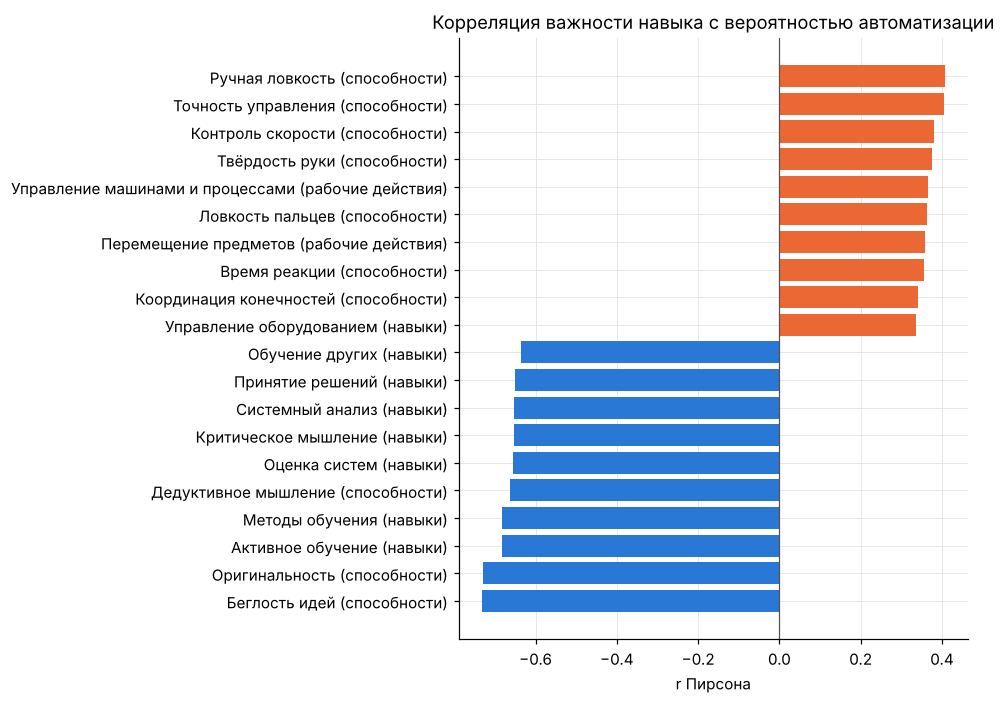

In [10]:
corr = df[FEATS].corrwith(df["automation_prob"]).sort_values()
nice = lambda c: f"{feature_ru(c)} ({GROUPS[c[:2]].lower()})" if c[:2] in GROUPS else feature_ru(c)
top = pd.concat([corr.head(10), corr.tail(10)])
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh([nice(c) for c in top.index], top.values, color=["#2a78d6" if v < 0 else "#eb6834" for v in top.values])
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Корреляция важности навыка с вероятностью автоматизации", xlabel="r Пирсона")
plt.tight_layout(); plt.show()

**Вывод.** Риск **снижают** творческие и аналитические способности: оригинальность, беглость идей, дедуктивное
мышление, активное обучение, критическое мышление, системный анализ и принятие решений (|r| ≈ 0,65–0,73).
Риск **повышают** физические и операционные способности: ручная ловкость, точность управления, работа с машинами,
перемещение предметов (r ≈ 0,33–0,41). Связь с защитными навыками заметно сильнее, чем с «опасными».

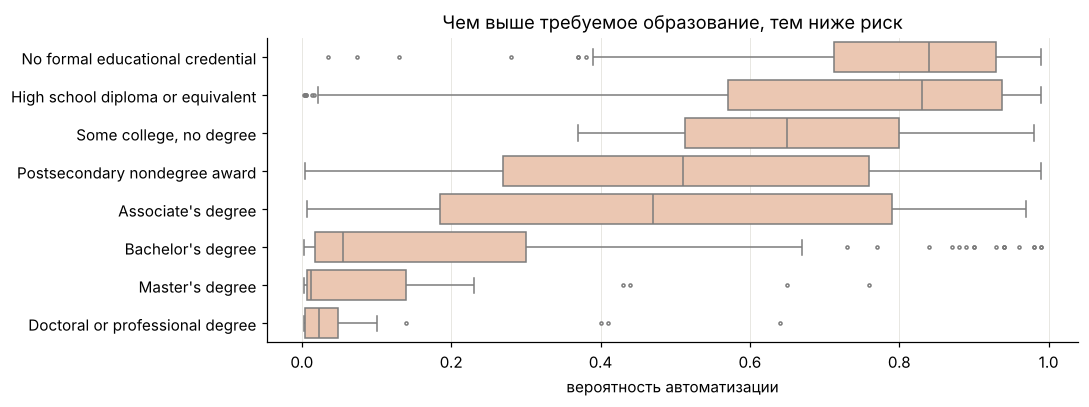

In [11]:
edu_order = ["No formal educational credential", "High school diploma or equivalent", "Some college, no degree",
             "Postsecondary nondegree award", "Associate's degree", "Bachelor's degree", "Master's degree",
             "Doctoral or professional degree"]
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.boxplot(data=df, y="education", x="automation_prob", order=edu_order, color="#f5c4a8", ax=ax, fliersize=2)
ax.set(title="Чем выше требуемое образование, тем ниже риск", xlabel="вероятность автоматизации", ylabel="")
plt.tight_layout(); plt.show()

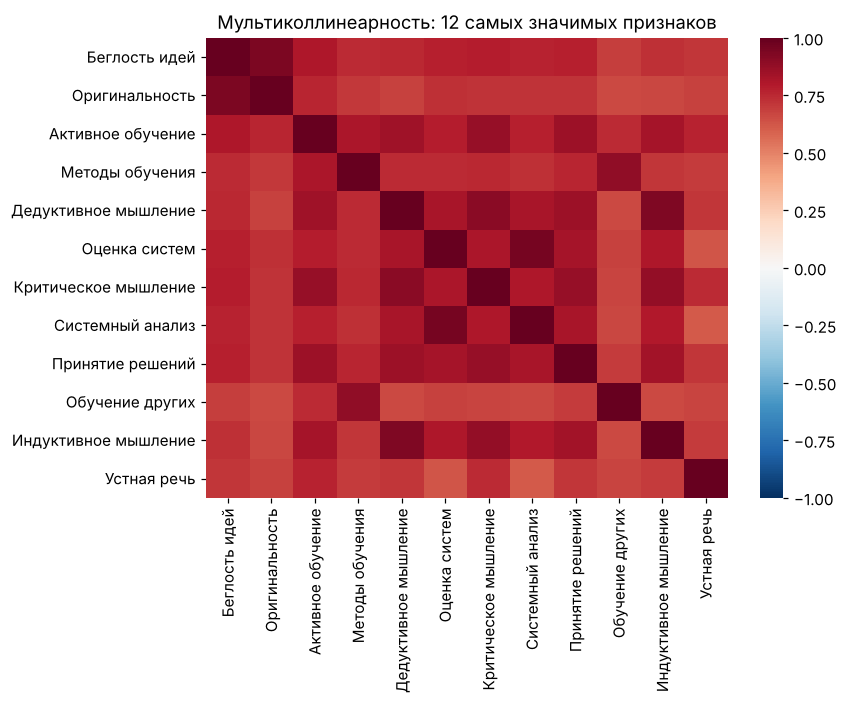

In [12]:
sub = df[[c for c in corr.abs().sort_values(ascending=False).index[:12]]]
plt.figure(figsize=(8, 6.5))
sns.heatmap(sub.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=[feature_ru(c)[:24] for c in sub],
            yticklabels=[feature_ru(c)[:24] for c in sub])
plt.title("Мультиколлинеарность: 12 самых значимых признаков"); plt.tight_layout(); plt.show()

Признаки сильно скоррелированы между собой (|r| до 0,9) — для линейной модели нужна регуляризация,
а важность признаков нужно трактовать осторожно (permutation importance «делит» вклад между близнецами).

### Вторая ось: генеративный ИИ
Frey & Osborne оценивали автоматизацию в 2013 году — до ChatGPT. Поэтому добавляем экспозицию к GenAI
(Eloundou et al., 2023: доля задач профессии, которые LLM ускоряет минимум вдвое).

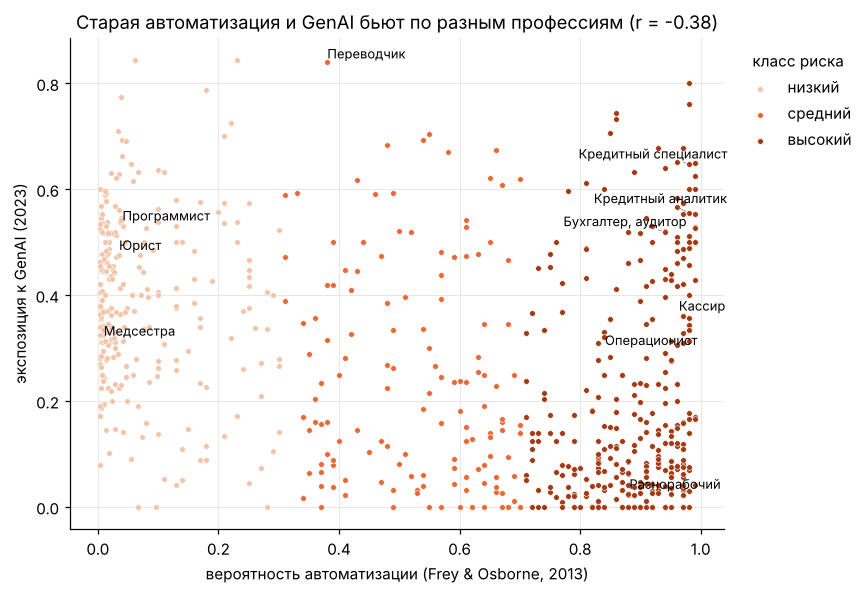

In [13]:
g = df.dropna(subset=["genai_exposure_human"])
r = g[["automation_prob", "genai_exposure_human"]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(8, 5.5))
for c in CLASSES:
    s = g[g["risk_class"] == c]
    ax.scatter(s["automation_prob"], s["genai_exposure_human"], s=14, color=RISK_COLORS[c], label=CLASS_RU[c],
               edgecolor="white", linewidth=0.4)
texts = []
for name, ru in [("Tellers", "Операционист"), ("Loan Officers", "Кредитный специалист"), ("Credit Analysts", "Кредитный аналитик"),
                 ("Accountants and Auditors", "Бухгалтер, аудитор"), ("Software Developers, Applications", "Программист"),
                 ("Cashiers", "Кассир"), ("Interpreters and Translators", "Переводчик"), ("Lawyers", "Юрист"),
                 ("Construction Laborers", "Разнорабочий"), ("Registered Nurses", "Медсестра")]:
    row = g[g["occupation"] == name]
    if len(row): texts.append(ax.text(row["automation_prob"].iloc[0], row["genai_exposure_human"].iloc[0], ru, fontsize=8.5))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="#888", lw=0.5))
ax.set(xlabel="вероятность автоматизации (Frey & Osborne, 2013)", ylabel="экспозиция к GenAI (2023)",
       title=f"Старая автоматизация и GenAI бьют по разным профессиям (r = {r:.2f})")
ax.legend(title="класс риска", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

**Ключевой инсайт для банков.** Корреляция отрицательная: классическая автоматизация била по ручному и
рутинному труду, а GenAI — по интеллектуальным офисным задачам. Банковские должности (операционист,
кредитный специалист, кредитный аналитик) находятся **в зоне риска по обеим осям** — это главный сигнал для HR.

### Три взгляда на угрозу ИИ по данным 2025–2026 (Anthropic Economic Index)
Метки Frey & Osborne — оценка 2013 года, а GPTs are GPTs — теоретическая возможность (2023). Проверим их
на свежих данных Anthropic, которые основаны на **реальном** использовании ИИ:
* `observed_exposure` — какая доля задач профессии уже реально выполняется с Claude (март 2026;
  автоматизация весит 1, помощь человеку — 0,5);
* `robot_exposure_index` — какую часть физических задач профессии уже могут делать существующие роботы (0–3, сентябрь 2026);
* `aei_automation_share` — в каком проценте использования ИИ **делает задачу за человека**, а не помогает ему (2025).

Эти показатели в модель **не входят** — это независимая проверка и дополнительные оси для HR.

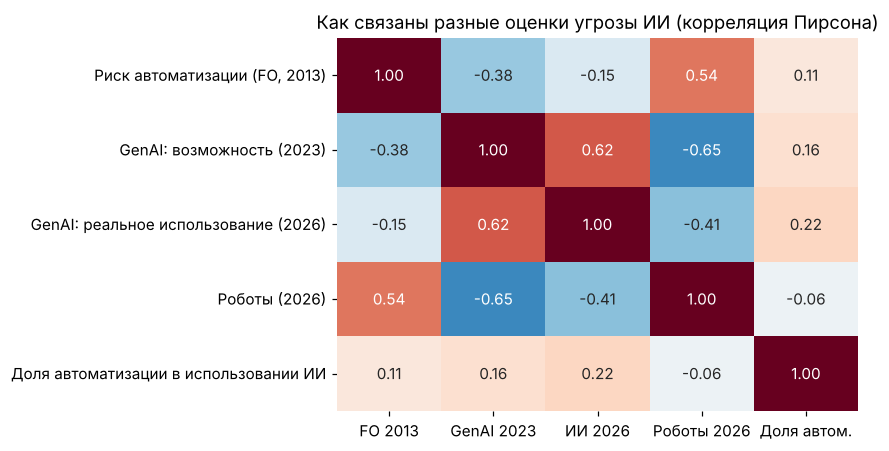

Покрытие показателей: {'automation_prob': 693, 'genai_exposure_human': 686, 'observed_exposure': 665, 'robot_exposure_index': 686, 'aei_automation_share': 426}


In [14]:
risk_cols = {"automation_prob": "Риск автоматизации (FO, 2013)", "genai_exposure_human": "GenAI: возможность (2023)",
             "observed_exposure": "GenAI: реальное использование (2026)", "robot_exposure_index": "Роботы (2026)",
             "aei_automation_share": "Доля автоматизации в использовании ИИ"}
short = dict(zip(risk_cols, ["FO 2013", "GenAI 2023", "ИИ 2026", "Роботы 2026", "Доля автом."]))
cm = df[list(risk_cols)].corr().rename(index=risk_cols, columns=short)
plt.figure(figsize=(8, 4.2))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False)
plt.title("Как связаны разные оценки угрозы ИИ (корреляция Пирсона)"); plt.tight_layout(); plt.show()
print("Покрытие показателей:", df[list(risk_cols)].notna().sum().to_dict())

**Выводы.**
1. **Свежие данные о роботах (2026) подтверждают метки 2013 года:** r ≈ 0,54 с вероятностью Frey & Osborne.
   Значит, «высокий риск» в нашей модели — это прежде всего риск для физического и рутинного труда, и он актуален сегодня.
2. **Теоретическая оценка GenAI подтверждается реальным использованием:** r ≈ 0,62 между GPTs are GPTs и наблюдаемой
   долей задач, которые люди уже делают с Claude.
3. **Роботы и GenAI — разные угрозы** (r ≈ −0,65): одни бьют по физическому труду, другие — по офисному.
   Поэтому HR нужны обе оси, а не одна оценка «риска ИИ».
4. **Это совпадает с данными Google** (AI & Economy ATLAS, июль 2026: 14,7 млн диалогов с Gemini за апрель 2026):
   ИИ используется в 68% профессий, но затрагивает в среднем лишь 21% их задач, а полную автоматизацию просят
   менее чем в 10% диалогов о нерутинной умственной работе. Открытых данных по профессиям Google не публикует,
   поэтому исследование используется только как внешнее подтверждение ([arXiv:2608.00038](https://arxiv.org/abs/2608.00038)).
5. **Где старые метки отстают от реальности:** у оператора call-центра модель (метки 2013) даёт средний риск,
   а по данным 2026 года ИИ уже выполняет ~70% его задач. Это видно в аудите штата ниже — HR стоит смотреть на все оси.

## 5. Feature engineering

In [15]:
COMPOSITES = {
    "fe_social": ["sk_Social Perceptiveness", "sk_Negotiation", "sk_Persuasion", "wa_Assisting and Caring for Others",
                  "sk_Coordination", "sk_Instructing"],
    "fe_creative": ["ab_Originality", "ab_Fluency of Ideas", "kn_Fine Arts", "wa_Thinking Creatively"],
    "fe_manual": ["ab_Finger Dexterity", "ab_Manual Dexterity", "ab_Arm-Hand Steadiness", "wa_Handling and Moving Objects"],
    "fe_routine_info": ["wa_Documenting/Recording Information", "wa_Processing Information", "kn_Clerical",
                        "wa_Performing Administrative Activities"],
    "fe_complex_cognitive": ["sk_Complex Problem Solving", "sk_Judgment and Decision Making", "sk_Critical Thinking",
                             "ab_Deductive Reasoning", "ab_Inductive Reasoning"],
}
def add_composites_df(X):
    X = X.copy()
    for k, cols in COMPOSITES.items():
        X[k] = X[cols].mean(axis=1)
    return X
df = add_composites_df(df)
df["fe_log_wage"] = np.log(df["median_wage"])
df["fe_education"] = df["education"].map({e: i for i, e in enumerate(edu_order)})
ENG = list(COMPOSITES) + ["fe_log_wage", "fe_education"]
print(df[ENG + ["automation_prob"]].corr()["automation_prob"].round(2).drop("automation_prob").sort_values())

fe_creative            -0.68
fe_complex_cognitive   -0.68
fe_education           -0.64
fe_social              -0.64
fe_log_wage            -0.55
fe_routine_info        -0.34
fe_manual               0.40
Name: automation_prob, dtype: float64


Составные индексы ведут себя как ожидалось: социальный и когнитивный — сильно против риска,
ручной и рутинно-информационный — за. Это ещё и понятный язык для HR-отчёта.

## 6. Разбиение и baseline

In [16]:
X_all = df[FEATS + ENG]; y = df["risk_class"]
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("train:", X_tr.shape, "test:", X_te.shape)

def evaluate(name, model, X=X_tr):
    s = cross_validate(model, X, y_tr, cv=cv, scoring=["f1_macro", "accuracy"], n_jobs=-1)
    return {"модель": name, "CV macro-F1": s["test_f1_macro"].mean(), "± std": s["test_f1_macro"].std(),
            "CV accuracy": s["test_accuracy"].mean()}

results = [evaluate("Dummy (самый частый класс)", DummyClassifier(strategy="most_frequent")),
           evaluate("Baseline: LogReg на 7 инженерных признаках",
                    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")), X_tr[ENG])]
pd.DataFrame(results).round(3)

train: (554, 168) test: (139, 168)


,модель,CV macro-F1,± std,CV accuracy
0,Dummy (самый частый класс),0.208,0.002,0.453
1,Baseline: LogReg на 7 инженерных признаках,0.626,0.055,0.662


## 7. Сравнение моделей
* **Logistic Regression** — линейная, интерпретируемая (коэффициенты = вклад навыка), нужна стандартизация.
* **Random Forest** — ансамбль деревьев, ловит нелинейности, устойчив к коррелированным признакам.
* **HistGradientBoosting** — бустинг: деревья обучаются последовательно на ошибках предыдущих.
* **SVM (RBF)** — хорошо работает на небольших выборках с большим числом признаков.

In [17]:
models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "RandomForest": RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE)),
}
for n, m in models.items(): results.append(evaluate(n + " (по умолчанию)", m))
res = pd.DataFrame(results).round(3); res

,модель,CV macro-F1,± std,CV accuracy
0,Dummy (самый частый класс),0.208,0.002,0.453
1,Baseline: LogReg на 7 инженерных признаках,0.626,0.055,0.662
2,LogReg (по умолчанию),0.619,0.043,0.659
3,RandomForest (по умолчанию),0.610,0.039,0.718
4,HistGradientBoosting (по умолчанию),0.628,0.024,0.735
5,SVM (RBF) (по умолчанию),0.632,0.030,0.689


## 8. Подбор гиперпараметров (GridSearchCV / RandomizedSearchCV, 5-fold CV, macro-F1)

In [18]:
searches = {
    "LogReg": GridSearchCV(models["LogReg"], {"logisticregression__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1],
                                               "logisticregression__penalty": ["l2"]}, cv=cv, scoring="f1_macro", n_jobs=-1),
    "RandomForest": RandomizedSearchCV(models["RandomForest"], {"n_estimators": [300, 500, 800], "max_depth": [None, 6, 10, 16],
                                       "min_samples_leaf": [1, 2, 4, 8], "max_features": ["sqrt", 0.2, 0.4]},
                                       n_iter=25, cv=cv, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": RandomizedSearchCV(models["HistGradientBoosting"], {"learning_rate": [0.02, 0.05, 0.1],
                                       "max_depth": [None, 3, 5], "max_leaf_nodes": [8, 15, 31], "l2_regularization": [0, 0.1, 1.0],
                                       "max_iter": [100, 200, 400]}, n_iter=25, cv=cv, scoring="f1_macro",
                                       random_state=RANDOM_STATE, n_jobs=-1),
    "SVM (RBF)": GridSearchCV(models["SVM (RBF)"], {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale", 0.003, 0.01]},
                              cv=cv, scoring="f1_macro", n_jobs=-1),
}
tuned = {}
rows = []
for n, s in searches.items():
    s.fit(X_tr, y_tr); tuned[n] = s.best_estimator_
    before = res.loc[res["модель"] == n + " (по умолчанию)", "CV macro-F1"].iloc[0]
    rows.append({"модель": n, "до": before, "после": s.best_score_, "прирост": s.best_score_ - before,
                 "лучшие параметры": {k.split("__")[-1]: v for k, v in s.best_params_.items()}})
tuning = pd.DataFrame(rows).round(3); tuning

,модель,до,после,прирост,лучшие параметры
0,LogReg,0.619,0.658,0.039,"{'C': 0.01, 'penalty': 'l2'}"
1,RandomForest,0.610,0.637,0.027,"{'n_estimators': 300, 'min_samples_leaf': 8, '..."
2,HistGradientBoosting,0.628,0.642,0.014,"{'max_leaf_nodes': 15, 'max_iter': 400, 'max_d..."
3,SVM (RBF),0.632,0.661,0.029,"{'C': 3, 'gamma': 0.01}"


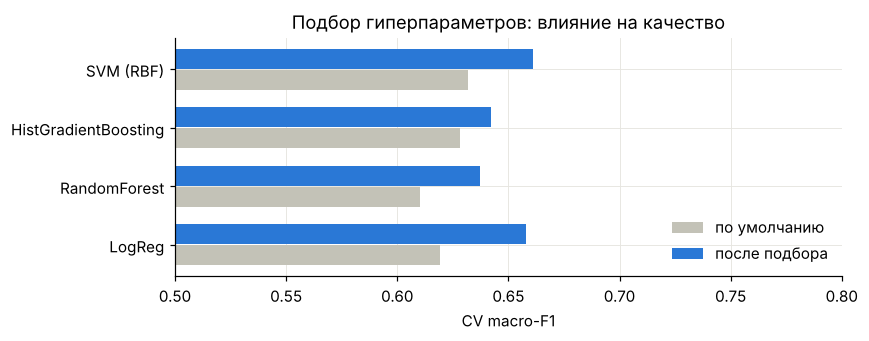

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(tuning))
ax.barh(yy - 0.18, tuning["до"], height=0.34, color="#c3c2b7", label="по умолчанию")
ax.barh(yy + 0.18, tuning["после"], height=0.34, color="#2a78d6", label="после подбора")
ax.set_yticks(yy, tuning["модель"]); ax.set_xlim(0.5, 0.8); ax.set_xlabel("CV macro-F1")
ax.set_title("Подбор гиперпараметров: влияние на качество"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 9. Итоговая модель на отложенной выборке

In [20]:
# правило выбора: лучшая по CV, но если LogReg хуже лучшей меньше чем на 1 std — берём LogReg (её можно объяснить HR)
top = tuning.sort_values("после", ascending=False).iloc[0]
best_std = searches[top["модель"]].cv_results_["std_test_score"][searches[top["модель"]].best_index_]
lr_score = tuning.set_index("модель").loc["LogReg", "после"]
best_name = "LogReg" if top["после"] - lr_score <= best_std else top["модель"]
print(f"Лучшая по CV: {top['модель']} ({top['после']:.3f} ± {best_std:.3f}); LogReg: {lr_score:.3f} → итоговая: {best_name}")
test_rows = []
for n, m in tuned.items():
    p = m.predict(X_te)
    test_rows.append({"модель": n, "test macro-F1": f1_score(y_te, p, average="macro"), "test accuracy": accuracy_score(y_te, p),
                      "recall «высокий»": recall_score(y_te, p, labels=["high"], average="macro")})
pd.DataFrame(test_rows).round(3)

Лучшая по CV: SVM (RBF) (0.661 ± 0.022); LogReg: 0.658 → итоговая: LogReg


,модель,test macro-F1,test accuracy,recall «высокий»
0,LogReg,0.681,0.712,0.746
1,RandomForest,0.684,0.741,0.905
2,HistGradientBoosting,0.716,0.770,0.873
3,SVM (RBF),0.666,0.719,0.841


Выбор итоговой модели делаем **по кросс-валидации**, а не по тесту. После подбора LogReg и SVM почти равны
(разница меньше одного std), а логистическая регрессия **интерпретируема**: её коэффициенты прямо показывают,
какой навык снижает риск. Для HR-продукта это важнее, чем +0,01 к метрике.

Почему не по тесту:, а не по тесту (тест — 139 профессий, на нём легко
«выбрать» случайно повезшую модель). Тест используем один раз — для финальной оценки.

              precision    recall  f1-score   support

      низкий      0.927     0.792     0.854        48
     средний      0.359     0.500     0.418        28
     высокий      0.797     0.746     0.770        63

    accuracy                          0.712       139
   macro avg      0.694     0.679     0.681       139
weighted avg      0.753     0.712     0.728       139



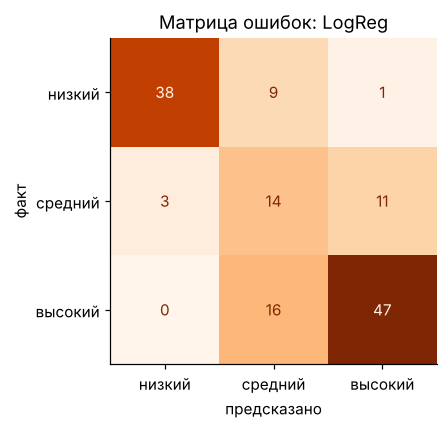

In [21]:
final = tuned[best_name]
pred = final.predict(X_te)
print(classification_report(y_te, pred, labels=CLASSES, target_names=[CLASS_RU[c] for c in CLASSES], digits=3))
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y_te, pred, labels=CLASSES, display_labels=[CLASS_RU[c] for c in CLASSES],
                                        cmap="Oranges", ax=ax, colorbar=False)
ax.set(title=f"Матрица ошибок: {best_name}", xlabel="предсказано", ylabel="факт"); ax.grid(False)
plt.tight_layout(); plt.show()

## 10. Анализ ошибок

In [22]:
err = df.loc[X_te.index, ["occupation", "automation_prob", "risk_class"]].copy()
err["pred"] = pred
err["p_high"] = final.predict_proba(X_te)[:, list(final.classes_).index("high")].round(2)
err["dist_to_threshold"] = np.minimum(abs(err["automation_prob"] - 0.3), abs(err["automation_prob"] - 0.7)).round(2)
wrong = err[err["risk_class"] != err["pred"]]
right = err[err["risk_class"] == err["pred"]]
print(f"Ошибок: {len(wrong)} из {len(err)}")
print("Средняя дистанция до порога: ошибки", wrong["dist_to_threshold"].mean().round(3),
      "| верные", right["dist_to_threshold"].mean().round(3))
print("Грубых ошибок (низкий <-> высокий):", ((wrong["risk_class"] != "medium") & (wrong["pred"] != "medium")).sum())
wrong.sort_values("dist_to_threshold", ascending=False).head(12)

Ошибок: 40 из 139
Средняя дистанция до порога: ошибки 0.129 | верные 0.2
Грубых ошибок (низкий <-> высокий): 1


,occupation,automation_prob,risk_class,pred,p_high,dist_to_threshold
691,Models,0.980,high,medium,0.47,0.28
99,"Hosts and Hostesses, Restaurant, Lounge and Co...",0.970,high,medium,0.45,0.27
241,Landscaping and Groundskeeping Workers,0.950,high,medium,0.29,0.25
595,Floral Designers,0.047,low,medium,0.32,0.25
73,First-Line Supervisors of Housekeeping and Jan...,0.940,high,medium,0.33,0.24
210,"Interviewers, Except Eligibility and Loan",0.940,high,medium,0.36,0.24
260,Cement Masons and Concrete Finishers,0.940,high,medium,0.49,0.24
346,Radio and Television Announcers,0.100,low,medium,0.16,0.20
607,Court Reporters,0.500,medium,high,0.88,0.20
247,Shoe and Leather Workers and Repairers,0.520,medium,high,0.70,0.18


**Где и почему модель ошибается.**
1. Большинство ошибок — **соседние классы** у профессий рядом с порогами 0,3 / 0,7: граница условная,
   а сама вероятность FO — тоже оценка с погрешностью.
2. **Средний класс** — самый слабый: он малочислен и по навыкам похож то на низкий, то на высокий.
3. Профессии, где риск зависит от **контекста, а не навыков** (например, продажи и обслуживание),
   модель путает: в O\*NET их профиль навыков почти как у защищённых профессий.

## 11. Какие навыки имеют наибольший вес
Признаки сильно скоррелированы, поэтому важность **отдельного** признака ненадёжна: модель может опереться на
любого из «близнецов». Используем **групповую permutation importance**: перемешиваем сразу всю группу признаков
и смотрим, насколько падает macro-F1 на тесте.

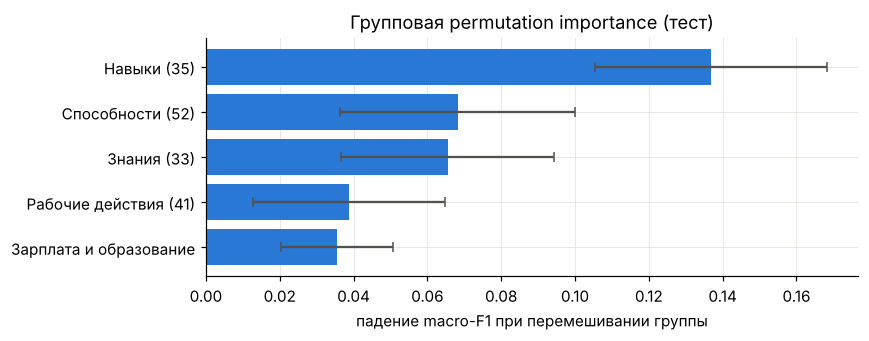

,Δ macro-F1,std
Зарплата и образование,0.035,0.015
Рабочие действия (41),0.039,0.026
Знания (33),0.066,0.029
Способности (52),0.068,0.032
Навыки (35),0.137,0.031


In [23]:
groups = {"Навыки (35)": [c for c in X_te if c.startswith("sk_")], "Знания (33)": [c for c in X_te if c.startswith("kn_")],
          "Способности (52)": [c for c in X_te if c.startswith("ab_")], "Рабочие действия (41)": [c for c in X_te if c.startswith("wa_")],
          "Зарплата и образование": ["fe_log_wage", "fe_education"]}
rng = np.random.default_rng(RANDOM_STATE)
base_f1 = f1_score(y_te, final.predict(X_te), average="macro")
gimp = {}
for gname, cols in groups.items():
    drops = []
    for _ in range(30):
        Xp = X_te.copy(); idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]
        drops.append(base_f1 - f1_score(y_te, final.predict(Xp), average="macro"))
    gimp[gname] = (np.mean(drops), np.std(drops))
gimp = pd.DataFrame(gimp, index=["Δ macro-F1", "std"]).T.sort_values("Δ macro-F1")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(gimp.index, gimp["Δ macro-F1"], xerr=gimp["std"], color="#2a78d6", ecolor="#52514e", capsize=3)
ax.set(title="Групповая permutation importance (тест)", xlabel="падение macro-F1 при перемешивании группы")
plt.tight_layout(); plt.show()
gimp.round(3)

Теперь — **какие именно навыки** отличают профессии высокого риска от низкого. Берём 35 навыков O\*NET
(то, чему можно учить) и считаем стандартизированную разницу средних (Cohen's d) между классами.

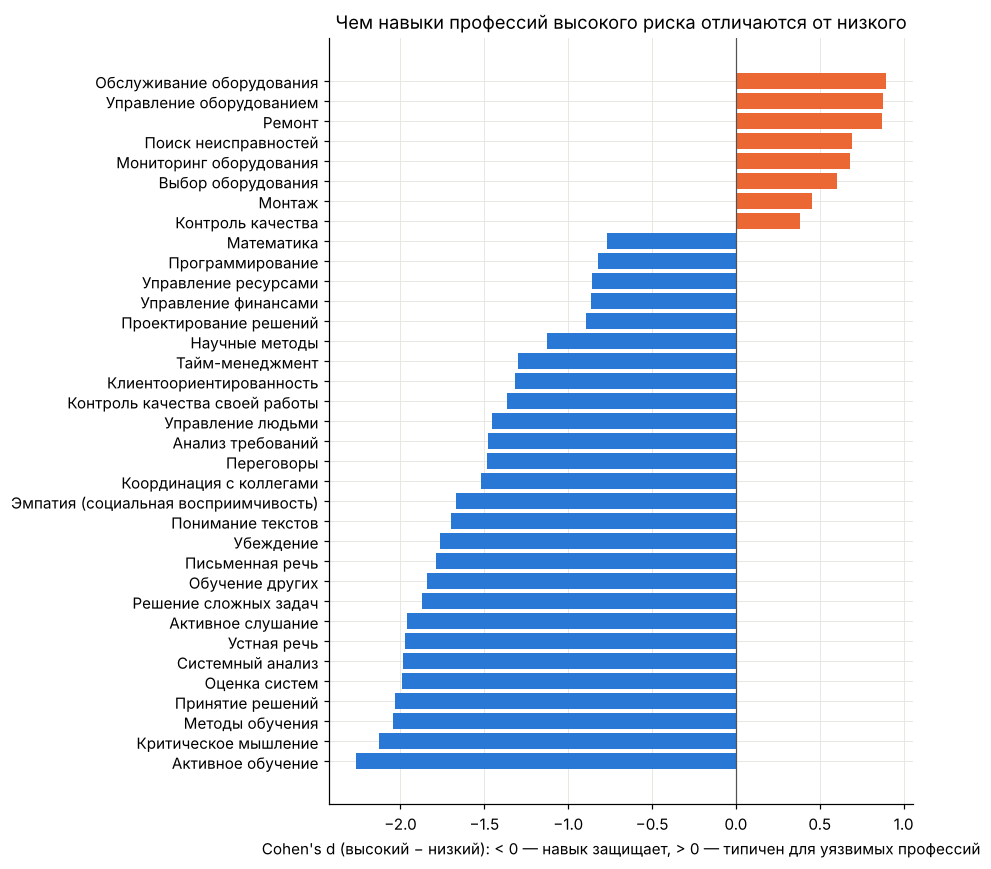

In [24]:
skill_cols = [c for c in FEATS if c.startswith("sk_")]
hi, lo = df[df["risk_class"] == "high"], df[df["risk_class"] == "low"]
pooled = np.sqrt((hi[skill_cols].var() + lo[skill_cols].var()) / 2)
d_eff = ((hi[skill_cols].mean() - lo[skill_cols].mean()) / pooled).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.barh([SKILL_RU[c[3:]] for c in d_eff.index], d_eff.values, color=["#2a78d6" if v < 0 else "#eb6834" for v in d_eff.values])
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Чем навыки профессий высокого риска отличаются от низкого",
       xlabel="Cohen's d (высокий − низкий): < 0 — навык защищает, > 0 — типичен для уязвимых профессий")
plt.tight_layout(); plt.show()

**Вывод для HR.** Сильнее всего защищают навыки мышления и работы с людьми: системный анализ и оценка систем,
принятие решений, критическое мышление, активное обучение, обучение других, решение сложных задач.
У профессий высокого риска выше только «операционные» навыки: управление оборудованием, мониторинг машин,
контроль качества, ремонт. Это совпадает с прогнозом WEF 2025: аналитическое мышление — главный ключевой навык,
а ручная ловкость и точность — навыки с самым большим падением спроса.

## 12. Проверка на «замкнутый круг»
Frey & Osborne сами получали вероятности моделью на 9 «узких местах» автоматизации из O\*NET
(ловкость пальцев и рук, оригинальность, изящные искусства, социальная восприимчивость, переговоры,
убеждение, забота о людях, тесное рабочее пространство). Если убрать их из признаков, сможет ли модель
всё равно предсказывать риск?

In [25]:
BOTTLENECK = ["ab_Finger Dexterity", "ab_Manual Dexterity", "ab_Originality", "kn_Fine Arts", "sk_Social Perceptiveness",
              "sk_Negotiation", "sk_Persuasion", "wa_Assisting and Caring for Others"]
drop = BOTTLENECK + ["fe_social", "fe_creative", "fe_manual"]
X_tr_nb = X_tr.drop(columns=drop)
nb = cross_val_score(final, X_tr_nb, y_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
full = cross_val_score(final, X_tr, y_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"CV macro-F1 со всеми признаками: {full.mean():.3f} | без «узких мест» FO: {nb.mean():.3f}")

CV macro-F1 со всеми признаками: 0.658 | без «узких мест» FO: 0.656


### Проверка: зависит ли результат от версии справочника?
Обучаем ту же модель на профилях навыков из старой версии O\*NET 24.0 (2019) на тех же профессиях.

In [26]:
import build_dataset as bd
from sklearn.model_selection import RepeatedStratifiedKFold
on24 = bd.load_onet("24")
X24 = pd.DataFrame({c: bd.onet_row(c, on24) for c in df["soc"]}).T.reindex(columns=FEATS)
X24.index = df.index
X24 = add_composites_df(X24.assign(fe_log_wage=df["fe_log_wage"], fe_education=df["fe_education"]))
ok = X24[FEATS].notna().all(axis=1)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)   # 25 разбиений, одинаковых для обеих версий
s31 = cross_val_score(final, X_all.loc[ok], y[ok], cv=rcv, scoring="f1_macro", n_jobs=-1)
s24 = cross_val_score(final, X24.loc[ok, FEATS + ENG], y[ok], cv=rcv, scoring="f1_macro", n_jobs=-1)
print(f"macro-F1: O*NET 31.0 (2026) = {s31.mean():.3f} ± {s31.std():.3f} | O*NET 24.0 (2019) = {s24.mean():.3f} ± {s24.std():.3f}")
print(f"Разница (24.0 − 31.0) на тех же разбиениях: {(s24 - s31).mean():+.3f} ± {(s24 - s31).std():.3f}")

macro-F1: O*NET 31.0 (2026) = 0.659 ± 0.044 | O*NET 24.0 (2019) = 0.693 ± 0.039
Разница (24.0 − 31.0) на тех же разбиениях: +0.033 ± 0.032


**Вывод.** На старой версии справочника модель немного точнее (≈ +0,02–0,03 macro-F1). Это ожидаемо: метки
Frey & Osborne построены в 2013 году на данных O\*NET того времени, и профили навыков той эпохи лучше с ними
согласуются. За 2019–2026 годы профили многих профессий изменились — это само по себе сигнал, что работа
меняется и оценки 2013 года стареют. Для продукта используем **актуальную версию 31.0**: HR важны сегодняшние
навыки, а потеря точности небольшая и в пределах разброса кросс-валидации.

Качество почти не падает → модель не просто «переоткрывает» формулу Frey & Osborne, а находит
риск в остальном профиле навыков.

## 13. Применение к рынку Кыргызстана (hh, октябрь 2026)

In [27]:
vac = pd.read_csv(DATA / "raw" / "hh_kg_vacancies.csv")
cnt = pd.read_csv(DATA / "raw" / "hh_kg_counts.csv")
hdr = cnt["search_header"].fillna("").str.replace("\u00a0", " ")
cnt["vacancies_kg"] = hdr.str.extract(r"Найден\w* (\d[\d ]*)")[0].str.replace(" ", "").astype(float).fillna(0).astype(int)
print("Вакансий собрано:", len(vac), "| должностей:", vac["query"].nunique(),
      "| с ключевыми навыками:", vac["skills"].notna().mean().round(2))

def parse_salary(s):
    """Медиана вилки в сомах; только помесячные зарплаты в сомах (₽/$/вахта/смена — вакансии за рубежом или другой формат)."""
    if not isinstance(s, str) or "сом" not in s or "за месяц" not in s: return np.nan
    nums = [float(re.sub(r"\D", "", x)) for x in re.findall(r"\d[\d\s\u00a0\u202f]*\d|\d", s)]
    return np.mean(nums) if nums else np.nan
vac["salary_kgs"] = vac["salary"].map(parse_salary)
print("Зарплата в сомах указана у", vac["salary_kgs"].notna().sum(), "вакансий;",
      "вакансий с оплатой в ₽ (работа в России для граждан КР):", vac["salary"].fillna("").str.contains("₽").sum())

lookup = df.set_index("soc")
# второй источник: lalafo.kg — крупнейшая доска объявлений КР (≈19 тыс. объявлений в разделе «Работа»).
# Поиск lalafo нечёткий: по запросу «кредитный аналитик» выдаёт тысячи нерелевантных объявлений.
# Поэтому оставляем только объявления, где название должности есть в заголовке (title_match),
# а общее число по должности берём, только если релевантна большая часть первой страницы выдачи.
lf = pd.read_csv(DATA / "raw" / "lalafo_kg_vacancies.csv")
lf_cnt = pd.read_csv(DATA / "raw" / "lalafo_kg_counts.csv")
lf = lf[lf["title_match"] == 1]
lf["salary_kgs"] = np.where((lf["currency"] == "KGS") & (lf["price"] >= 10000) & (lf["price"] <= 1_000_000), lf["price"], np.nan)
lf_recent = lf[pd.to_datetime(lf["created"]) >= "2026-04-01"]          # свежие объявления, последние ~6 месяцев
lf_cnt["match_rate"] = lf_cnt["title_matched"] / lf_cnt["page_items"].replace(0, np.nan)
# total = 10000 — это потолок выдачи lalafo, а не реальное число; такие значения считаем ненадёжными
reliable = (lf_cnt["match_rate"] >= 0.6) & (lf_cnt["total"] < 5000)
lf_cnt["vacancies_lalafo"] = np.where(reliable, lf_cnt["total"], lf_cnt["title_matched"]).astype(int)
print("lalafo: релевантных объявлений", len(lf), "| свежих (с апреля 2026):", len(lf_recent),
      "| с зарплатой:", lf_recent["salary_kgs"].notna().sum())
print("Должности, по которым на lalafo нет релевантных объявлений:",
      ", ".join(lf_cnt.loc[lf_cnt["title_matched"] == 0, "query"]))

sal = pd.concat([vac[["query", "salary_kgs"]], lf_recent[["query", "salary_kgs"]]])
kg = cnt.merge(lf_cnt[["query", "vacancies_lalafo"]], on="query", how="left") \
        .merge(sal.groupby("query").agg(median_salary_kgs=("salary_kgs", "median")).reset_index(), on="query", how="left")
kg["vacancies_lalafo"] = kg["vacancies_lalafo"].fillna(0).astype(int)
kg["vacancies_total"] = kg["vacancies_kg"] + kg["vacancies_lalafo"]
kg = kg[kg["soc"].isin(lookup.index)].copy()
proba = final.predict_proba(lookup.loc[kg["soc"], FEATS + ENG])
kg["pred_class"] = final.classes_[proba.argmax(1)]
kg["p_high"] = proba[:, list(final.classes_).index("high")]
kg["genai_exposure"] = lookup.loc[kg["soc"], "genai_exposure_human"].values
kg["observed_exposure"] = lookup.loc[kg["soc"], "observed_exposure"].values
kg["robot_exposure"] = lookup.loc[kg["soc"], "robot_exposure_index"].values
kg["ai_automation_share"] = lookup.loc[kg["soc"], "aei_automation_share"].values
kg[["query", "group", "vacancies_kg", "vacancies_lalafo", "median_salary_kgs", "pred_class", "p_high", "genai_exposure"]] \
    .sort_values("p_high", ascending=False).round(2)

Вакансий собрано: 390 | должностей: 59 | с ключевыми навыками: 0.73
Зарплата в сомах указана у 181 вакансий; вакансий с оплатой в ₽ (работа в России для граждан КР): 26
lalafo: релевантных объявлений 551 | свежих (с апреля 2026): 360 | с зарплатой: 106
Должности, по которым на lalafo нет релевантных объявлений: Кредитный аналитик, Специалист по работе с клиентами, Финансовый консультант, Комплаенс, Риск-менеджер, Финансовый аналитик, Аналитик данных, Data scientist, Специалист по информационной безопасности, Системный администратор, Главный бухгалтер, Аудитор, Экономист, HR менеджер, Секретарь, Страховой агент, Менеджер проектов


,query,group,vacancies_kg,vacancies_lalafo,median_salary_kgs,pred_class,p_high,genai_exposure
15,Бухгалтер,bank,210,143,55000.0,high,0.88,0.31
0,Операционист,bank,29,5,36500.0,high,0.88,0.33
25,Офис-менеджер,bank,78,19,40000.0,high,0.85,0.50
26,Секретарь,bank,74,0,37500.0,high,0.79,0.57
5,Коллектор,bank,2,9,NaN,high,0.74,0.43
43,Повар,other,43,992,65000.0,high,0.69,0.12
1,Кредитный специалист,bank,30,1,NaN,high,0.67,0.65
27,Кассир,other,66,116,35000.0,high,0.66,0.36
51,Страховой агент,other,2,0,35000.0,high,0.63,0.53
17,Аудитор,bank,15,0,72500.0,high,0.60,0.52


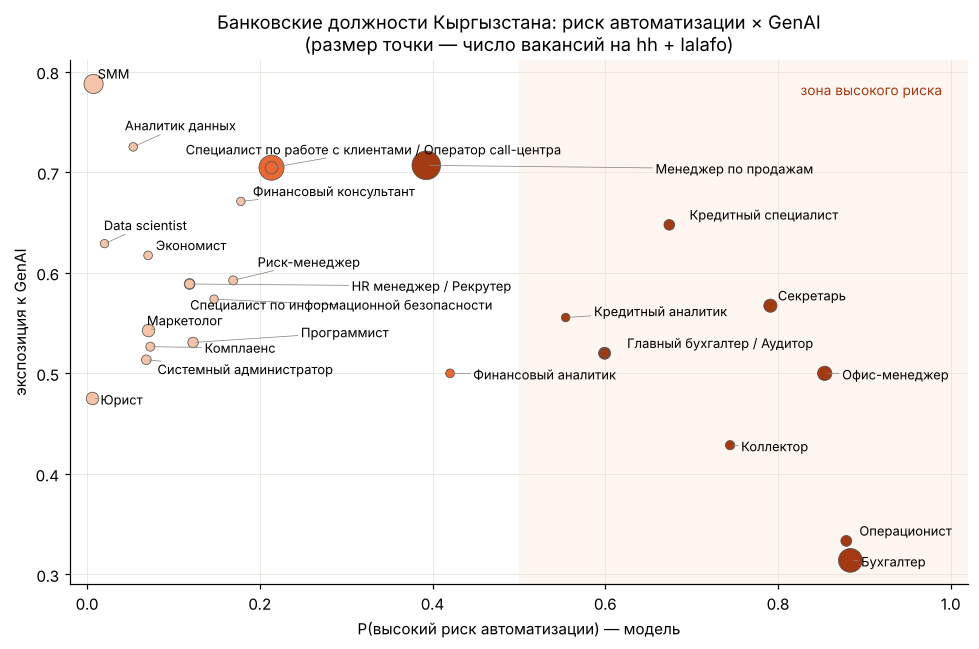

In [28]:
bank = kg[kg["group"] == "bank"].dropna(subset=["genai_exposure"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.axvspan(0.5, 1.02, ymin=0, ymax=1, color="#fbe3d6", alpha=0.35, lw=0)
ax.scatter(bank["p_high"], bank["genai_exposure"], s=30 + bank["vacancies_total"].clip(upper=600) * 0.6,
           color=[RISK_COLORS[c] for c in bank["pred_class"]], edgecolor="#52514e", linewidth=0.5)
lab = bank.groupby("soc").agg(name=("query", " / ".join), x=("p_high", "first"), y=("genai_exposure", "first"))
texts = [ax.text(r_.x, r_.y, r_.name, fontsize=8.5) for r_ in lab.itertuples()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="#888", lw=0.5))
ax.text(0.99, 0.79, "зона высокого риска", ha="right", va="top", fontsize=9, color="#a33a12")
ax.set(xlim=(-0.02, 1.02), xlabel="P(высокий риск автоматизации) — модель", ylabel="экспозиция к GenAI",
       title="Банковские должности Кыргызстана: риск автоматизации × GenAI\n(размер точки — число вакансий на hh + lalafo)")
plt.tight_layout(); plt.show()

### Что сейчас просят работодатели Кыргызстана

In [29]:
sk = vac.dropna(subset=["skills"]).assign(skill=lambda d: d["skills"].str.split("|")).explode("skill")
sk["skill"] = sk["skill"].str.strip()
top_sk = sk.groupby("group")["skill"].value_counts().groupby(level=0).head(15)
top_sk

group  skill                              
bank   Деловое общение                        37
       Работа с большим объемом информации    21
       Телефонные переговоры                  21
       Деловая переписка                      19
       Заключение договоров                   16
       Аналитическое мышление                 16
       Активные продажи                       15
       1С: Бухгалтерия                        12
       Русский — C2 — В совершенстве          12
       Деловая коммуникация                   12
       Кыргызский — C2 — В совершенстве       11
       1С: Предприятие 8                      10
       Холодные продажи                       10
       Точность и внимательность к деталям    10
       Работа с документами                    9
other  Умение работать в коллективе           23
       Деловое общение                        22
       Обучение и развитие                    21
       Точность и внимательность к деталям    18
       Работа в команде   

## 14. Продукт: аудит штата и план переобучения

In [30]:
def add_composites(X):
    X = X.copy()
    for k, cols in COMPOSITES.items():
        X[k] = X[cols].mean(axis=1)
    return X

def risk_score(X):
    """Ожидаемый уровень риска: P(высокий) + 0.5 * P(средний), от 0 до 1."""
    p = final.predict_proba(X)
    return p[:, list(final.classes_).index("high")] + 0.5 * p[:, list(final.classes_).index("medium")]

def reskilling_plan(soc, k=3, step=1.0):
    """What-if: поднимаем каждый обучаемый навык на 1 балл (макс. 5) и смотрим, насколько падает риск."""
    base = lookup.loc[[soc], FEATS + ENG]
    r0 = risk_score(base)[0]
    gains = {}
    for s_ in TRAINABLE:
        X = base.copy(); X["sk_" + s_] = np.minimum(X["sk_" + s_] + step, 5)
        gains[s_] = r0 - risk_score(add_composites(X)[FEATS + ENG])[0]
    return pd.Series(gains).sort_values(ascending=False).head(k)

# «Куда переводить»: ближайшие по профилю навыков должности рынка КР с низким риском
Z = StandardScaler().fit(df[FEATS])
def transition_targets(soc, k=3, group=None):
    cand = kg[(kg["pred_class"] == "low") & (kg["soc"] != soc)]
    if group: cand = cand[cand["group"] == group]
    cand = cand.drop_duplicates("soc")
    a = Z.transform(lookup.loc[[soc], FEATS]); b = Z.transform(lookup.loc[cand["soc"], FEATS])
    sim = (b @ a.T).ravel() / (np.linalg.norm(b, axis=1) * np.linalg.norm(a))
    return cand.assign(similarity=sim).sort_values("similarity", ascending=False).head(k)[["query", "soc", "similarity"]]

def skill_gap(soc_from, soc_to, k=4):
    """Обучаемые навыки, которых не хватает для перехода, с поправкой на мировые тренды (WEF 2025 и LinkedIn 2025–2026)."""
    gap = pd.Series({s_: lookup.loc[soc_to, "sk_" + s_] - lookup.loc[soc_from, "sk_" + s_] for s_ in TRAINABLE})
    score = gap.clip(lower=0) * pd.Series({s_: trend_weight(s_) for s_ in TRAINABLE})
    top_ = score.sort_values(ascending=False).head(k).index
    tags = lambda s_: ", ".join(([f"WEF: {WEF_TREND[s_]}"] if s_ in WEF_TREND else []) + (["LinkedIn: растёт"] if s_ in LINKEDIN_TREND else []))
    return [f"{SKILL_RU[s_]} (+{gap[s_]:.1f}{'; ' + tags(s_) if tags(s_) else ''})" for s_ in top_]

for pos in ["Операционист", "Кредитный специалист", "Бухгалтер"]:
    soc = cnt.loc[cnt["query"] == pos, "soc"].iloc[0]
    t = transition_targets(soc, 3, group="bank")
    print(f"\n{pos} → куда переводить:")
    for _, r_ in t.iterrows():
        print(f"   {r_['query']:<35} сходство {r_['similarity']:.2f} | развивать: {'; '.join(skill_gap(soc, r_['soc'], 3))}")

def audit_company(staff: pd.DataFrame, group="bank") -> pd.DataFrame:
    """staff: столбцы position (как в hh-запросе) и headcount."""
    m = staff.merge(cnt[["query", "soc"]], left_on="position", right_on="query", how="left")
    m = m[m["soc"].isin(lookup.index)].copy()
    pr = final.predict_proba(lookup.loc[m["soc"], FEATS + ENG])
    m["класс риска"] = [CLASS_RU[c] for c in final.classes_[pr.argmax(1)]]
    m["P(высокий)"] = pr[:, list(final.classes_).index("high")].round(2)
    m["GenAI"] = lookup.loc[m["soc"], "genai_exposure_human"].round(2).values
    m["ИИ сейчас"] = lookup.loc[m["soc"], "observed_exposure"].round(2).values
    m["роботы"] = lookup.loc[m["soc"], "robot_exposure_index"].round(2).values
    at_risk = m["класс риска"] != "низкий"
    tgt = [transition_targets(s_, 1, group) if r_ else None for s_, r_ in zip(m["soc"], at_risk)]
    m["куда переводить"] = [t["query"].iloc[0] if t is not None and len(t) else "—" for t in tgt]
    m["чему учить"] = [", ".join(x.split(" (")[0] for x in skill_gap(s_, t["soc"].iloc[0], 3))
                      if t is not None and len(t) else "—" for s_, t in zip(m["soc"], tgt)]
    return m[["position", "headcount", "класс риска", "P(высокий)", "GenAI", "ИИ сейчас", "роботы", "куда переводить", "чему учить"]] \
        .sort_values("P(высокий)", ascending=False)

# Иллюстративный пример: условный банк на 300 человек (структура придумана для демонстрации)
demo_bank = pd.DataFrame({"position": ["Операционист", "Кассир", "Оператор call-центра", "Кредитный специалист", "Кредитный аналитик",
                                       "Коллектор", "Бухгалтер", "Финансовый аналитик", "Риск-менеджер", "Комплаенс",
                                       "Аналитик данных", "Программист", "Юрист", "HR менеджер", "Маркетолог"],
                          "headcount": [70, 25, 40, 45, 12, 15, 18, 8, 7, 6, 6, 20, 6, 6, 6]})
report = audit_company(demo_bank)
share_high = report.loc[report["класс риска"] == "высокий", "headcount"].sum() / report["headcount"].sum()
print(f"Доля штата в зоне высокого риска: {share_high:.0%}")
report


Операционист → куда переводить:
   Финансовый консультант              сходство 0.49 | развивать: Системный анализ (+1.3; WEF: растёт, LinkedIn: растёт); Анализ требований (+1.4; WEF: ключевой, LinkedIn: растёт); Оценка систем (+1.0; WEF: растёт, LinkedIn: растёт)
   Риск-менеджер                       сходство 0.39 | развивать: Системный анализ (+1.1; WEF: растёт, LinkedIn: растёт); Активное обучение (+0.9; WEF: растёт, LinkedIn: растёт); Программирование (+0.9; WEF: растёт, LinkedIn: растёт)
   HR менеджер                         сходство 0.35 | развивать: Системный анализ (+0.9; WEF: растёт, LinkedIn: растёт); Переговоры (+1.1; WEF: ключевой, LinkedIn: растёт); Методы обучения (+0.8; WEF: растёт)

Кредитный специалист → куда переводить:
   Финансовый консультант              сходство 0.79 | развивать: Оценка систем (+1.1; WEF: растёт, LinkedIn: растёт); Системный анализ (+0.8; WEF: растёт, LinkedIn: растёт); Анализ требований (+0.8; WEF: ключевой, LinkedIn: растёт)
   Риск-менеджер

,position,headcount,класс риска,P(высокий),GenAI,ИИ сейчас,роботы,куда переводить,чему учить
0,Операционист,70,высокий,0.88,0.33,0.02,1.12,Финансовый консультант,"Системный анализ, Анализ требований, Оценка си..."
6,Бухгалтер,18,высокий,0.88,0.31,0.31,0.07,Финансовый консультант,"Оценка систем, Системный анализ, Убеждение"
5,Коллектор,15,высокий,0.74,0.43,0.30,0.00,HR менеджер,"Методы обучения, Оценка систем, Системный анализ"
3,Кредитный специалист,45,высокий,0.67,0.65,0.19,0.00,Финансовый консультант,"Оценка систем, Системный анализ, Анализ требов..."
1,Кассир,25,высокий,0.66,0.36,0.08,1.00,HR менеджер,"Активное обучение, Решение сложных задач, Сист..."
4,Кредитный аналитик,12,высокий,0.55,0.56,0.17,0.00,Риск-менеджер,"Обучение других, Решение сложных задач, Управл..."
7,Финансовый аналитик,8,средний,0.42,0.50,0.57,0.00,Экономист,"Обучение других, Методы обучения, Управление л..."
2,Оператор call-центра,40,средний,0.21,0.70,0.70,0.00,HR менеджер,"Системный анализ, Переговоры, Письменная речь"
8,Риск-менеджер,7,низкий,0.17,0.59,0.22,0.00,—,—
13,HR менеджер,6,низкий,0.12,0.59,0.40,0.00,—,—


## 15. Сохранение модели для демо

In [31]:
Path("models").mkdir(exist_ok=True)
joblib.dump({"model": final, "features": FEATS + ENG, "classes": list(final.classes_), 
             "composites": COMPOSITES, "edu_order": edu_order}, "models/risk_model.joblib")
df.to_csv(DATA / "processed" / "occupations_model_ready.csv", index=False)
kg.to_csv(DATA / "processed" / "kg_positions_scored.csv", index=False)
print("Сохранено: models/risk_model.joblib")

Сохранено: models/risk_model.joblib


## 16. Ограничения
* Метки — оценка Frey & Osborne для США 2013 года, а не факт сокращений; в Кыргызстане скорость внедрения ИИ ниже,
  поэтому результат — это **относительный рейтинг уязвимости**, а не прогноз «через N лет уволят».
* Профили навыков из O\*NET (США); для должностей КР используется соответствие по коду SOC, сделанное вручную.
* GenAI-экспозиция показывает, где ИИ может **изменить** работу, — это не обязательно сокращение.
* Вакансии hh — срез на одну дату, первые 8 вакансий выдачи; не все работодатели КР публикуются на hh.